# Pengujian Prediksi Audio: SAWMIL vs NON SAWMIL
## Proyek Sains Data (PSD) - Klasifikasi Audio

Notebook ini digunakan untuk **menguji dan memprediksi file audio baru (`.mp3` / `.wav`)** yang Anda masukkan ke dalam folder **`test/`**.

### Alur Pengujian:
1. Memuat model terbaik yang sudah dilatih (`model_terbaik_klasifikasi_audio.joblib`).
2. Melakukan ekstraksi **74 fitur audio Librosa** (MFCC, Chroma, Spectral Centroid, Bandwidth, Rolloff, ZCR, RMS).
3. Menerapkan **Audio Normalization (AGC)** agar suara yang direkam dari HP atau jarak jauh tetap terdeteksi akurat.
4. Mengeluarkan hasil prediksi: **SAWMIL** atau **NON SAWMIL**, beserta persentase keyakinan model dan visualisasi spektrum suara.

### 1. Import Library yang Dibutuhkan

In [1]:
import os
import numpy as np
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt
import joblib
from IPython.display import Audio, display
import warnings

warnings.filterwarnings('ignore')

### 2. Memuat Model Klasifikasi Terbaik

In [2]:
MODEL_PATH = 'model_terbaik_klasifikasi_audio.joblib'

if os.path.exists(MODEL_PATH):
    model = joblib.load(MODEL_PATH)
    print(f"✅ Model berhasil dimuat: {type(model).__name__}")
    print(f"   Target Classes: {getattr(model, 'classes_', ['0 (NON SAWMIL)', '1 (SAWMIL)'] )}")
else:
    raise FileNotFoundError(f"File model '{MODEL_PATH}' tidak ditemukan! Pastikan Anda sudah menjalankan klasifikasi-audio.ipynb terlebih dahulu.")

✅ Model berhasil dimuat: Pipeline
   Target Classes: [0 1]


### 3. Definisi Fungsi Ekstraksi 74 Fitur Librosa & Normalisasi (AGC)

In [3]:
# 74 Kolom fitur persis sesuai urutan training
FEATURE_COLUMNS = [
    'mfcc_1_mean', 'mfcc_1_std', 'mfcc_2_mean', 'mfcc_2_std', 'mfcc_3_mean', 'mfcc_3_std',
    'mfcc_4_mean', 'mfcc_4_std', 'mfcc_5_mean', 'mfcc_5_std', 'mfcc_6_mean', 'mfcc_6_std',
    'mfcc_7_mean', 'mfcc_7_std', 'mfcc_8_mean', 'mfcc_8_std', 'mfcc_9_mean', 'mfcc_9_std',
    'mfcc_10_mean', 'mfcc_10_std', 'mfcc_11_mean', 'mfcc_11_std', 'mfcc_12_mean', 'mfcc_12_std',
    'mfcc_13_mean', 'mfcc_13_std', 'mfcc_14_mean', 'mfcc_14_std', 'mfcc_15_mean', 'mfcc_15_std',
    'mfcc_16_mean', 'mfcc_16_std', 'mfcc_17_mean', 'mfcc_17_std', 'mfcc_18_mean', 'mfcc_18_std',
    'mfcc_19_mean', 'mfcc_19_std', 'mfcc_20_mean', 'mfcc_20_std',
    'chroma_1_mean', 'chroma_1_std', 'chroma_2_mean', 'chroma_2_std', 'chroma_3_mean', 'chroma_3_std',
    'chroma_4_mean', 'chroma_4_std', 'chroma_5_mean', 'chroma_5_std', 'chroma_6_mean', 'chroma_6_std',
    'chroma_7_mean', 'chroma_7_std', 'chroma_8_mean', 'chroma_8_std', 'chroma_9_mean', 'chroma_9_std',
    'chroma_10_mean', 'chroma_10_std', 'chroma_11_mean', 'chroma_11_std', 'chroma_12_mean', 'chroma_12_std',
    'spectral_centroid_mean', 'spectral_centroid_std',
    'spectral_bandwidth_mean', 'spectral_bandwidth_std',
    'spectral_rolloff_mean', 'spectral_rolloff_std',
    'zcr_mean', 'zcr_std',
    'rms_mean', 'rms_std'
]

def extract_audio_features(file_path, sr=22050, n_mfcc=20):
    """
    Mengekstrak 74 fitur Librosa dari satu file audio dengan AGC Normalization.
    """
    # 1. Load audio
    y, sr = librosa.load(file_path, sr=sr)
    if y.ndim > 1:
        y = np.mean(y, axis=1)
        
    # 2. Hitung RMS murni dan Normalisasi AGC (menghilangkan pengaruh volume speaker HP)
    raw_rms = float(np.sqrt(np.mean(y**2)))
    max_amp = float(np.max(np.abs(y)))
    if max_amp > 1e-4:
        y_proc = (y / max_amp) * 0.70
    else:
        y_proc = y + np.random.normal(0, 1e-6, size=len(y)).astype(np.float32)

    features = {}

    # 1. MFCC (20)
    mfcc = librosa.feature.mfcc(y=y_proc, sr=sr, n_mfcc=n_mfcc)
    for i in range(n_mfcc):
        features[f'mfcc_{i+1}_mean'] = float(np.mean(mfcc[i]))
        features[f'mfcc_{i+1}_std'] = float(np.std(mfcc[i]))

    # 2. Chroma STFT (12)
    chroma = librosa.feature.chroma_stft(y=y_proc, sr=sr)
    for i in range(chroma.shape[0]):
        features[f'chroma_{i+1}_mean'] = float(np.mean(chroma[i]))
        features[f'chroma_{i+1}_std'] = float(np.std(chroma[i]))

    # 3. Spectral Centroid
    spec_cent = librosa.feature.spectral_centroid(y=y_proc, sr=sr)
    features['spectral_centroid_mean'] = float(np.mean(spec_cent))
    features['spectral_centroid_std'] = float(np.std(spec_cent))

    # 4. Spectral Bandwidth
    spec_bw = librosa.feature.spectral_bandwidth(y=y_proc, sr=sr)
    features['spectral_bandwidth_mean'] = float(np.mean(spec_bw))
    features['spectral_bandwidth_std'] = float(np.std(spec_bw))

    # 5. Spectral Rolloff
    spec_rolloff = librosa.feature.spectral_rolloff(y=y_proc, sr=sr)
    features['spectral_rolloff_mean'] = float(np.mean(spec_rolloff))
    features['spectral_rolloff_std'] = float(np.std(spec_rolloff))

    # 6. ZCR
    zcr = librosa.feature.zero_crossing_rate(y=y_proc)
    features['zcr_mean'] = float(np.mean(zcr))
    features['zcr_std'] = float(np.std(zcr))

    # 7. RMS
    rms = librosa.feature.rms(y=y_proc)
    features['rms_mean'] = float(np.mean(rms))
    features['rms_std'] = float(np.std(rms))

    return features, raw_rms, y, sr

### 4. Fungsi Prediksi Satu File Audio (`predict_single_audio`)

In [4]:
def predict_audio(file_path, plot=True):
    """
    Memprediksi apakah satu file audio adalah SAWMIL atau NON SAWMIL.
    """
    if not os.path.exists(file_path):
        print(f"❌ File tidak ditemukan: {file_path}")
        return None

    # Ekstraksi fitur
    feat, raw_rms, y, sr = extract_audio_features(file_path)
    df_row = pd.DataFrame([feat])[FEATURE_COLUMNS]

    # Prediksi model
    pred_class = int(model.predict(df_row)[0])
    label_name = "SAWMIL" if pred_class == 1 else "NON SAWMIL"

    # Hitung probabilitas
    if hasattr(model, 'predict_proba'):
        probs = model.predict_proba(df_row)[0]
        prob_sawmil = probs[1] * 100
        prob_nonsawmil = probs[0] * 100
        confidence = prob_sawmil if pred_class == 1 else prob_nonsawmil
    else:
        confidence = 100.0
        prob_sawmil = 100.0 if pred_class == 1 else 0.0
        prob_nonsawmil = 0.0 if pred_class == 1 else 100.0

    duration = len(y) / sr

    print("=" * 60)
    print(f"🎵 File: {os.path.basename(file_path)} (Durasi: {duration:.2f}s)")
    print(f"🎯 HASIL PREDIKSI : {'⚠️ SAWMIL (Mesin Gergaji)' if pred_class == 1 else '🛡️ NON SAWMIL (Bukan Gergaji)'}")
    print(f"📊 Keyakinan Model: {confidence:.2f}%")
    print(f"   - Probabilitas SAWMIL     : {prob_sawmil:.2f}%")
    print(f"   - Probabilitas NON SAWMIL : {prob_nonsawmil:.2f}%")
    print(f"   - Spectral Centroid       : {feat['spectral_centroid_mean']:.1f} Hz")
    print(f"   - Zero Crossing Rate      : {feat['zcr_mean']:.4f}")
    print("=" * 60)

    # Player audio langsung di Jupyter
    display(Audio(data=y, rate=sr))

    # Plot Visualisasi Waveform & Mel-Spectrogram
    if plot:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 3.5))
        
        # Waveform
        color_wave = 'red' if pred_class == 1 else 'green'
        librosa.display.waveshow(y, sr=sr, ax=ax1, color=color_wave)
        ax1.set_title(f'Waveform: {os.path.basename(file_path)}')
        
        # Mel-Spectrogram
        s_mel = librosa.feature.melspectrogram(y=y, sr=sr)
        s_db = librosa.power_to_db(s_mel, ref=np.max)
        img = librosa.display.specshow(s_db, sr=sr, x_axis='time', y_axis='mel', ax=ax2, cmap='magma')
        ax2.set_title(f'Mel-Spectrogram [Prediksi: {label_name}]')
        fig.colorbar(img, ax=ax2, format='%+2.0f dB')
        
        plt.tight_layout()
        plt.show()

    return {
        'filename': os.path.basename(file_path),
        'prediksi': label_name,
        'confidence': round(confidence, 2),
        'prob_sawmil': round(prob_sawmil, 2),
        'prob_nonsawmil': round(prob_nonsawmil, 2),
        'spectral_centroid': round(feat['spectral_centroid_mean'], 1),
        'zcr': round(feat['zcr_mean'], 4)
    }

### 5. Pengujian Seluruh Audio dalam Folder `test/` (Batch Testing)

> Masukkan file-file audio (`.mp3` atau `.wav`) yang ingin Anda uji ke dalam folder **`test/`**, lalu jalankan cell di bawah ini.

📂 Ditemukan 2 file audio di folder 'test/':
   1. gergaji.mp3
   2. just dance.mp3

--- Memulai Pengujian Seluruh File Audio ---

🎵 File: gergaji.mp3 (Durasi: 31.69s)
🎯 HASIL PREDIKSI : ⚠️ SAWMIL (Mesin Gergaji)
📊 Keyakinan Model: 76.48%
   - Probabilitas SAWMIL     : 76.48%
   - Probabilitas NON SAWMIL : 23.52%
   - Spectral Centroid       : 3013.5 Hz
   - Zero Crossing Rate      : 0.1495


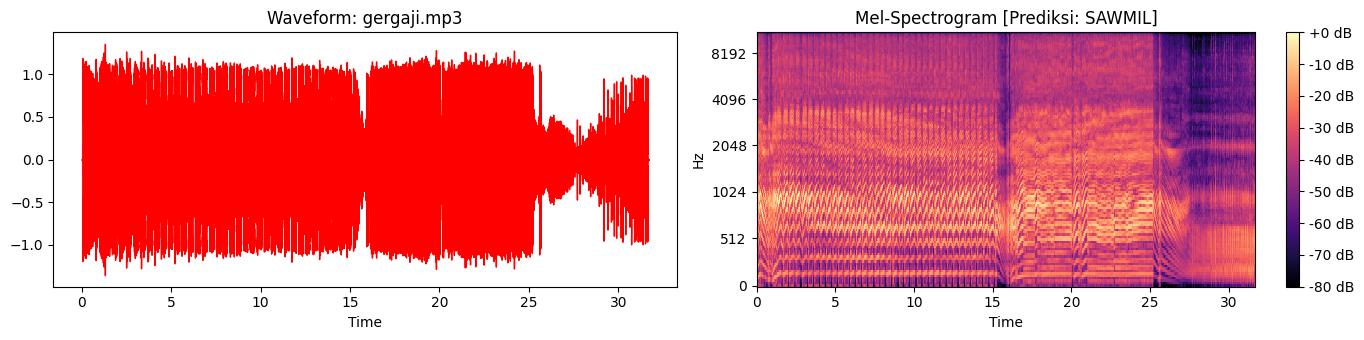

🎵 File: just dance.mp3 (Durasi: 24.84s)
🎯 HASIL PREDIKSI : 🛡️ NON SAWMIL (Bukan Gergaji)
📊 Keyakinan Model: 86.52%
   - Probabilitas SAWMIL     : 13.48%
   - Probabilitas NON SAWMIL : 86.52%
   - Spectral Centroid       : 2485.3 Hz
   - Zero Crossing Rate      : 0.1362


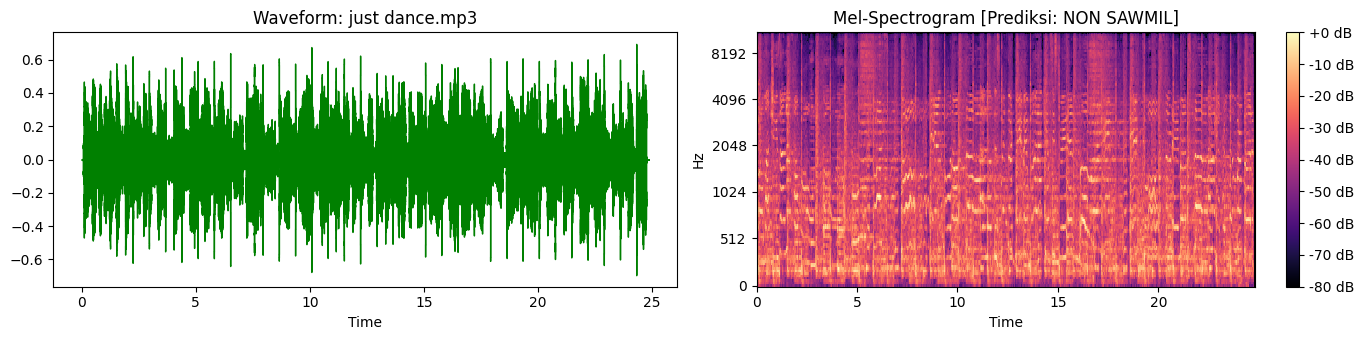


=================== RINGKASAN HASIL PENGUJIAN ===================


,filename,prediksi,confidence,prob_sawmil,prob_nonsawmil,spectral_centroid,zcr
0,gergaji.mp3,SAWMIL,76.48,76.48,23.52,3013.5,0.1495
1,just dance.mp3,NON SAWMIL,86.52,13.48,86.52,2485.3,0.1362



💾 Hasil ringkasan berhasil disimpan ke: 'hasil_prediksi_test.csv'


In [6]:
TEST_FOLDER = 'test'

# Cek file audio yang ada di folder test
supported_ext = ('.mp3', '.wav', '.ogg', '.m4a')
test_files = [f for f in os.listdir(TEST_FOLDER) if f.lower().endswith(supported_ext)]

if len(test_files) == 0:
    print(f"⚠️ Folder '{TEST_FOLDER}/' saat ini masih kosong.")
    print("👉 Silakan copy/paste file MP3 yang ingin diuji ke dalam folder 'test/', lalu jalankan cell ini kembali!")
else:
    print(f"📂 Ditemukan {len(test_files)} file audio di folder '{TEST_FOLDER}/':")
    for idx, f in enumerate(test_files, 1):
        print(f"   {idx}. {f}")
    
    print("\n--- Memulai Pengujian Seluruh File Audio ---\n")
    results = []
    for f in test_files:
        full_path = os.path.join(TEST_FOLDER, f)
        res = predict_audio(full_path, plot=True)
        if res:
            results.append(res)
            
    # Ringkasan hasil dalam bentuk Tabel Pandas DataFrame
    df_results = pd.DataFrame(results)
    print("\n=================== RINGKASAN HASIL PENGUJIAN ===================")
    display(df_results)
    
    # Simpan hasil prediksi ke file CSV
    output_csv = 'hasil_prediksi_test.csv'
    df_results.to_csv(output_csv, index=False)
    print(f"\n💾 Hasil ringkasan berhasil disimpan ke: '{output_csv}'")

### 6. Contoh Pengujian Satu File Spesifik
Gunakan fungsi ini jika Anda ingin menguji satu file audio tertentu secara cepat:

In [ ]:
# Ganti nama file di bawah ini sesuai nama file audio Anda di dalam folder test
contoh_file = os.path.join('test', 'contoh_audio.mp3')

if os.path.exists(contoh_file):
    predict_audio(contoh_file, plot=True)
else:
    print(f"File '{contoh_file}' belum ada. Masukkan file audio ke folder test lalu ganti nama filenya di cell ini.")